# Petit exemple : une unite, un delestage, une demande constante

Un jeu minimal pour voir comment la borne inferieure converge, formulation intervalle contre 3-bin :

* une **unite** de capacite 10 et de cout lineaire 1, avec un **cout fixe** de 1 par periode ou elle est
  allumee (pas de cout de demarrage), **initialement eteinte**, avec des **rampes** (variation maximale de
  production d'une periode a l'autre) egales a `RAMPE` = 1 ;
* un **delestage** de cout 2 par unite de demande non servie ;
* une **demande constante** egale a 15, sans aleas.

Dans ce modele la production au demarrage est limitee a la production minimale `PMIN`, puis augmente d'au
plus `RAMPE` par periode, dans la limite de la capacite. Avec `PMIN = 1` et `RAMPE = 1`, l'unite demarree a la
periode 1 produit 1, 2, 3, 4... et le delestage couvre le reste : le cout de la periode t vaut
1 x p_t + 1 (cout fixe) + 2 x (15 - p_t), ou p_t est la production de l'unite. Avec `RAMPE = PMAX` il n'y a plus de contrainte
de rampe : la production monte directement a 10.

La borne de l'iteration k utilise les coupes des iterations 1 a k-1. Converger « en une iteration »
signifie donc que la borne de l'iteration 2 est deja l'optimum.

Question : une coupe suffit-elle encore avec des rampes, pour chaque formulation ?

In [8]:
using MSUC, Gurobi, Printf, Random

GRB_ENV = Gurobi.Env()
optimizer = () -> Gurobi.Optimizer(GRB_ENV)

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05


#34 (generic function with 1 method)

## L'instance

Dans MSUC le cout du delestage est une constante du package (700). Pour avoir un delestage a cout 2,
on le represente par une **deuxieme unite** de cout 2, de capacite superieure a la demande, et
**toujours allumee** (duree minimale d'allumage egale a l'horizon) : le prix de la demande vaut alors
toujours 2, comme si le delestage etait un parametre. (On a verifie que cela donne les memes bornes
qu'un vrai delestage a cout 2.)

`PMIN` doit etre strictement positive : pour une unite eteinte dont la production initiale vaut
`PMIN = 0`, les contraintes d'engagement actuelles sont infaisables.

In [9]:
T              = 4      # horizon (nombre de periodes)
DEMANDE        = 15.0   # demande constante
PMAX           = 10.0   # capacite de l'unite
PMIN           = 1.0    # production minimale (et production au demarrage) ; 10.0 : l'unite est tout ou rien
RAMPE          = 1.0    # rampes montante et descendante de l'unite ; PMAX : pas de contrainte de rampe
COUT           = 1.0    # cout lineaire de l'unite
COUT_FIXE      = 1.0    # cout fixe de l'unite, paye a chaque periode ou elle est allumee
COUT_DELESTAGE = 2.0    # cout du delestage

function toy_instance(T)
    # pas de cout de demarrage ; cfixe : cout fixe par periode allumee ; statut initial < 0 : eteinte,
    # >= 0 : allumee ; minup : duree minimale d'allumage
    unite(nom, pmin, pmax, rampe, cout, cfixe, p0, statut, minup) = MSUC.ThermalUnit(
        nom, 1,            # nom, noeud du reseau
        pmin, pmax,        # production minimale, maximale
        rampe, rampe,      # rampes montante, descendante
        0.0, 0.0,          # cout de demarrage, d'arret
        cout, cfixe,       # cout lineaire, cout fixe (par periode allumee)
        p0, statut,        # production et statut initiaux
        minup, 1,          # duree minimale d'allumage, d'arret
        MSUC.set_intervals(minup, statut, p0, pmin, rampe, T),
    )
    unites = [
        unite(1, PMIN, PMAX, RAMPE, COUT, COUT_FIXE, 0.0, -1, 1),                                        # l'unite, eteinte
        unite(2, 0.0, 2 * DEMANDE, 2 * DEMANDE, COUT_DELESTAGE, 0.0, DEMANDE, 1, T + 1),           # le delestage, toujours allumee
    ]
    return MSUC.Instance("toy", T, length(unites), unites, MSUC.IntervalIndex(unites),
        Dict{Tuple{Int,Int},MSUC.Line}(), [Int[]], [fill(DEMANDE, T)], MSUC.ARMAProcess(1; S = 1), optimizer)
end

instance = toy_instance(T)
@printf("%d unites, %d et %d intervalles possibles, T = %d\n", instance.N,
        length(instance.Thermalunits[1].intervals), length(instance.Thermalunits[2].intervals), T)

2 unites, 10 et 5 intervalles possibles, T = 4


In [10]:
# intervalles [a, b] d'une unite, a partir de son statut aux periodes 0, ..., T : allumee aux periodes
# a, ..., b-1 (a = 0 : deja allumee au debut ; b = T+1 : jusqu'a la fin)
function intervalles(statut)
    res = Tuple{Int,Int}[]
    t = 0
    while t < length(statut)
        if statut[t + 1] > 0.5
            a = t
            while t < length(statut) && statut[t + 1] > 0.5
                t += 1
            end
            push!(res, (a, t))
        else
            t += 1
        end
    end
    return res
end
texte(ints) = isempty(ints) ? "aucun" : join(["[$a, $b]" for (a, b) in ints], " ")

# l'unite demarre a la periode 1 a PMIN, monte de RAMPE par periode jusqu'a PMAX et reste allumee ; le
# delestage couvre le reste (pour T = 1, l'unite eteinte coute autant : solution optimale degeneree)
production = [min(PMAX, PMIN + (t - 1) * RAMPE) for t in 1:T]
a_la_main = sum(COUT * p + COUT_FIXE + COUT_DELESTAGE * (DEMANDE - p) for p in production)
resultat = MSUC.multistage_extensive(instance; gap = 1e-9, timelimit = 60)
exact = resultat[1]
statut_optimal = [resultat[4][1][1, t] for t in 0:T]       # statut de l'unite 1 aux periodes 0, ..., T
@printf("production de l'unite : %s\n", join([@sprintf("%.0f", p) for p in production], ", "))
@printf("optimum a la main = %.2f ; optimum exact (programme etendu) = %.2f\n", a_la_main, exact)
@printf("intervalles de l'unite 1 dans la solution optimale : %s\n", texte(intervalles(statut_optimal)))

production de l'unite : 1, 2, 3, 4
optimum a la main = 110.00 ; optimum exact (programme etendu) = 110.00
intervalles de l'unite 1 dans la solution optimale : [1, 5]


## Entrainement : intervalle contre 3-bin

On entraine cinq iterations avec chaque formulation. Pour chaque iteration on affiche la borne et les
**intervalles [a, b] de l'unite 1 selectionnes** par le probleme racine : l'unite est allumee aux periodes
a, ..., b-1 (b = T+1 : jusqu'a la fin ; « aucun » : l'unite reste eteinte). Ce planning est celui de
l'iteration k, calcule avec les coupes des iterations 1 a k-1 ; la borne de l'iteration k en est la valeur.
En 3-bin le probleme racine n'a pas de variables d'intervalle : on lit les intervalles sur le statut de
l'unite.

On affiche aussi le nombre de coupes (une par iteration) necessaires pour que la borne atteigne l'optimum.

In [11]:
METHODES = [
    ("intervalle", MSUC.subproblem_builder_UC_extended, MSUC.ExtendedFormulation),
    ("3-bin",      MSUC.subproblem_builder_UC_def,      MSUC.SDDPFormulation),
]

# renvoie les bornes, le cout de la politique simulee et le planning x^k de chaque iteration
function entraine(instance, builder, method; iterations = 5)
    model = MSUC.PolicyGraph(builder, instance, 1.0, MSUC.Graph(instance.TimeHorizon + 1), method;
                             lower_bound = 0.0, optimizer = optimizer)
    plannings = MSUC.Schedule[]
    Random.seed!(MSUC.SEED)
    MSUC.train(model; iteration_limit = iterations, print_level = 0, run_numerical_stability_report = false,
               post_iteration_callback = result -> push!(plannings, model.schedule))
    bornes = [l.bound for l in model.most_recent_training_results.log]
    return (bornes = bornes, cout = MSUC.simulate(model).cost, plannings = plannings)
end

# nombre d'iterations de coupes pour atteindre l'optimum (la borne de l'iteration k en utilise k-1)
function iterations_de_coupes(bornes, opt)
    k = findfirst(b -> b >= opt - 1e-6, bornes)
    return k === nothing ? "pas atteint" : string(k - 1)
end

resultats = Dict{String,Vector{Float64}}()
for (nom, builder, method) in METHODES
    r = entraine(instance, builder, method)
    resultats[nom] = r.bornes
    println(nom)
    @printf("   iteration   borne      intervalles de l'unite 1 selectionnes\n")
    for k in eachindex(r.bornes)
        @printf("   %9d  %8.2f   %s\n", k, r.bornes[k], texte(intervalles(r.plannings[k].u[1, :])))
    end
    @printf("   iterations de coupes pour atteindre l'optimum : %s ; cout de la politique : %.2f\n",
            iterations_de_coupes(r.bornes, exact), r.cout)
end

intervalle
   iteration   borne      intervalles de l'unite 1 selectionnes
           1      0.00   aucun
           2    110.00   [1, 5]
           3    110.00   [1, 5]
           4    110.00   [1, 5]
           5    110.00   [1, 5]
   iterations de coupes pour atteindre l'optimum : 1 ; cout de la politique : 110.00
3-bin
   iteration   borne      intervalles de l'unite 1 selectionnes
           1      0.00   aucun
           2     80.00   [1, 5]
           3    110.00   [1, 5]
           4    110.00   [1, 5]
           5    110.00   [1, 5]
   iterations de coupes pour atteindre l'optimum : 2 ; cout de la politique : 110.00


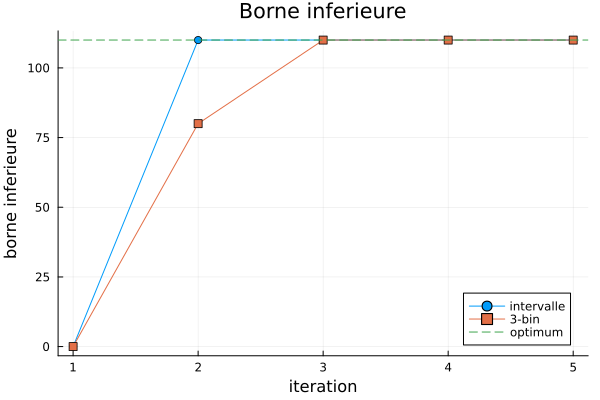

In [12]:
using Plots
plot(resultats["intervalle"], label = "intervalle", marker = :circle, xlabel = "iteration",
     ylabel = "borne inferieure", title = "Borne inferieure")
plot!(resultats["3-bin"], label = "3-bin", marker = :square)
hline!([exact], label = "optimum", linestyle = :dash)

## Effet de l'horizon

Meme exemple pour T de 1 a 5 : optimum et intervalles de la solution optimale, puis, pour chaque
formulation, les bornes et les intervalles selectionnes aux quatre premieres iterations.

In [15]:
for T_ in 1:5
    inst = toy_instance(T_)
    res = MSUC.multistage_extensive(inst; gap = 1e-9, timelimit = 60)
    opt = res[1]
    @printf("T = %d, optimum %.0f ; intervalles de l'unite 1 dans la solution optimale : %s\n", T_, opt,
            texte(intervalles([res[4][1][1, t] for t in 0:T_])))
    for (nom, builder, method) in METHODES
        r = entraine(inst, builder, method; iterations = 4)
        @printf("   %-10s bornes %s   -> iterations de coupes : %s\n", nom,
                join([@sprintf("%.0f", b) for b in r.bornes], "  "), iterations_de_coupes(r.bornes, opt))
        @printf("   %-10s intervalles selectionnes : %s\n", "",
                join([texte(intervalles(p.u[1, :])) for p in r.plannings], "  |  "))
    end
end

T = 1, optimum 29 ; intervalles de l'unite 1 dans la solution optimale : [1, 2]
   intervalle bornes 0  29  29  29   -> iterations de coupes : 1
              intervalles selectionnes : aucun  |  [1, 2]  |  [1, 2]  |  [1, 2]
   3-bin      bornes 0  20  29  29   -> iterations de coupes : 2
              intervalles selectionnes : aucun  |  [1, 2]  |  [1, 2]  |  [1, 2]
T = 2, optimum 57 ; intervalles de l'unite 1 dans la solution optimale : [1, 3]
   intervalle bornes 0  57  57  57   -> iterations de coupes : 1
              intervalles selectionnes : aucun  |  [1, 3]  |  [1, 3]  |  [1, 3]
   3-bin      bornes 0  40  57  57   -> iterations de coupes : 2
              intervalles selectionnes : aucun  |  [1, 3]  |  [1, 3]  |  [1, 3]
T = 3, optimum 84 ; intervalles de l'unite 1 dans la solution optimale : [1, 4]
   intervalle bornes 0  84  84  84   -> iterations de coupes : 1
              intervalles selectionnes : [2, 3]  |  [1, 4]  |  [1, 4]  |  [1, 4]
   3-bin      bornes 0  60  84  84